#Tests for .in files

##MSD visualizer

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from utilities import read_msd_dat, msd_time_averaged, fit_power_law, read_type_names, read_dump_com_typed

# The notebook runs from DPD tissue/code
CODE_DIR = Path.cwd()
RUN_DIR = CODE_DIR / "runs/cell"
GRAPHS_DIR = CODE_DIR.parent / "graphs"

DT = 0.01        # must match `timestep` in the input script

# Settings
run = RUN_DIR    # run folder with msd_mito.dat and dump.m1
RC_UM = 0.25     # bead size r_c in micrometres
FIT_FROM = 0.01   # fit lags above this fraction of the longest lag
TAU_S = None     # DPD time unit in seconds (after calibration)

from utilities import read_msd_dat, msd_time_averaged, fit_power_law, read_type_names, read_dump_com_typed

NAME = "cell"   # in_name you gave Run(...)

names = read_type_names(run / f"{NAME}.data")
steps, msd_lmp = read_msd_dat(run / "msd_org.dat")
t_lmp = steps * DT
dsteps, com, mol_ids, types = read_dump_com_typed(run / f"dump.{NAME}")
lags, msd_all, per_org = msd_time_averaged(com)
t = lags * (dsteps[1] - dsteps[0]) * DT
late = t >= FIT_FROM * t[-1]
msd_lmp = msd_lmp[:, mol_ids - 1]   # chunk ID = molecule ID, so columns line up with com

print(f"{com.shape[1]} organelles, {len(dsteps)} frames, lag up to {t[-1]:.1f} tau")
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
results = {}
for k, ty in enumerate(np.unique(types)):
    sel = types == ty
    name, color = names.get(ty, f"type {ty}"), f"C{k}"
    msd = per_org[:, sel].mean(axis=1)
    alpha, _ = fit_power_law(t[late], msd[late])
    D_sim = np.polyfit(t[late], msd[late], 1)[0] / 6
    results[name] = (alpha, D_sim)
    line = f"{name:15s} n = {sel.sum():3d}  alpha = {alpha:.3f}  D_sim = {D_sim:.4g} r_c^2/tau"
    if TAU_S:
        line += f"  D = {D_sim * RC_UM**2 / TAU_S:.4g} um^2/s"
    print(line)
    ax[0].plot(t_lmp, msd_lmp[:, sel], color=color, lw=0.5, alpha=0.3)
    ax[0].plot(t_lmp, msd_lmp[:, sel].mean(axis=1), color=color, lw=2, label=name)
    ax[1].loglog(t, per_org[:, sel], color=color, lw=0.5, alpha=0.3)
    ax[1].loglog(t, msd, "o-", color=color, ms=3, label=f"{name}, alpha = {alpha:.2f}")
ax[0].set(xlabel="t (tau)", ylabel="MSD (r_c^2)", title="LAMMPS msd/chunk")
ax[1].set(xlabel="lag (tau)", ylabel="MSD (r_c^2)", title="Time-averaged MSD from dump")
ax[0].legend(); ax[1].legend()
fig.tight_layout()
GRAPHS_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(GRAPHS_DIR / f"{NAME}_msd.png", dpi=150)

KeyboardInterrupt: 

###No membrane

In [ ]:
from utilities import Run, Type

run = Run("test_run", "m1_crowded_mix", [40, 40, 8])
run.add_type(Type("mitochondrion", 12, "capsule", r=1.0, l=8.0, rel_density=1.1))
run.add_type(Type("vesicle", 20, "sphere", r=1.0, rel_density=1.05, a_cyto=35.0))
run.fill_cytoplasm(3.0)
run.write_data_file()
run.write_input_file(steps=200000, dump_every=1000, thermo_every=1000)

###With membrane

In [ ]:
from utilities import Run, Type

run = Run("runs/cell", "cell", BOX=[24, 24, 24])
run.add_type(Type("membrane", 1, "shell", r=10.0, a_cyto=50.0))  
run.add_type(Type("nucleus", 1, "sphere", r=4.0, rel_density=1.10, a_cyto=40.0))
run.add_type(Type("mitochondrion", 12, "capsule", r=1.0, l=8.0, rel_density=1.1))
run.add_type(Type("vesicle", 20, "sphere", r=1.0, rel_density=1.05, a_cyto=35.0))
run.fill_cytoplasm(RHO=3)
run.write_data_file()
run.write_input_file()

###Fat globules

In [ ]:
from utilities import Run, Type
import numpy as np

kT, eta = 1.380649e-23 * 295, 4.0           # J, Pa s
def D_um2_s(d_um):                           # Stokes-Einstein, d = diameter in um
    return kT / (6 * np.pi * eta * d_um / 2 * 1e-6) * 1e12

run = Run("provolone_run", "provolone", [50, 50, 50])
sizes = [("fat_10um", 10.0, 40, 1.0), ("fat_3um", 3.0, 100, 0.5), ("fat_1um", 1.0, 400, 0.5)]
for name, d, n, s in sizes:                  # big ones first so they fit
    run.add_type(Type(name, n, "sphere", r=d / 2, s=s))
run.fill_cytoplasm(0.0)                      # no solvent beads; this just sets run.cyto to empty
run.write_data_file()
for t, (_, d, _, _) in zip(run.types, sizes):
    n_beads = len(t.beads(t.positions[0]))
    print(t.atom_type, t.name, "D =", D_um2_s(d), "bead mass =", 1.0 * 0.1 / D_um2_s(d) / n_beads)
run.write_input_file(steps=100000, dump_every=1000, thermo_every=1000)

2 fat_10um D = 1.0803741390390045e-05 bead mass = 17.97291792399551
3 fat_3um D = 3.6012471301300145e-05 bead mass = 22.57573836794558
4 fat_1um D = 0.00010803741390390043 bead mass = 132.2293247265384


###Cell msd

34 objects, 251 frames, lag up to 500.0 tau, fit 6.0-124.0 tau
nucleus         n =   1  alpha = 0.996  D_sim = 0.001499 r_c^2/tau
mitochondrion   n =  12  alpha = 1.163  D_sim = 0.009224 r_c^2/tau
vesicle         n =  20  alpha = 0.928  D_sim = 0.009917 r_c^2/tau
cell drift             alpha = 1.399  (removed from the curves above)


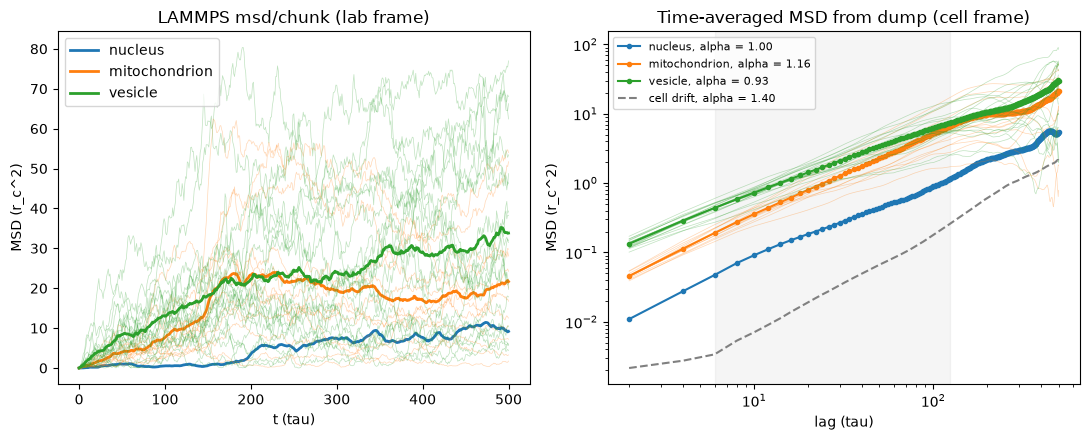

In [ ]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from utilities import read_msd_dat, msd_time_averaged, fit_power_law, read_type_names, read_dump_com_typed

# The notebook runs from DPD tissue/code
CODE_DIR = Path.cwd()
GRAPHS_DIR = CODE_DIR.parent / "graphs"

# Settings
NAME = "cell"                # in_name you gave Run(...)
run = CODE_DIR / "runs/cell" # run folder with msd_org.dat, dump.<NAME> and <NAME>.data
DT = 0.01                    # must match `timestep` in the input script
RC_UM = 0.25                 # bead size r_c in micrometres
FIT_FROM = 0.01              # fit lags above this fraction of the longest lag
FIT_TO = 0.25                # ...and below this fraction (few time origins beyond it)
TAU_S = None                 # DPD time unit in seconds (after calibration)

names = read_type_names(run / f"{NAME}.data")
steps, msd_lmp = read_msd_dat(run / "msd_org.dat")
t_lmp = steps * DT
dsteps, com, mol_ids, types = read_dump_com_typed(run / f"dump.{NAME}")
msd_lmp = msd_lmp[:, mol_ids - 1]   # chunk ID = molecule ID, so columns line up with com

# Cell frame: subtract the membrane's centre of mass so the cell's own drift is removed
mem_ty = next((k for k, v in names.items() if v == "membrane"), None)
drift = None
if mem_ty is not None:
    cell = com[:, types == mem_ty]                      # (frames, 1, 3)
    _, drift, _ = msd_time_averaged(cell)
    com = com - cell
lags, msd_all, per_org = msd_time_averaged(com)
t = lags * (dsteps[1] - dsteps[0]) * DT
fit = (t >= FIT_FROM * t[-1]) & (t <= FIT_TO * t[-1])

print(f"{com.shape[1]} objects, {len(dsteps)} frames, lag up to {t[-1]:.1f} tau, fit {t[fit][0]:.1f}-{t[fit][-1]:.1f} tau")
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
results = {}
for k, ty in enumerate(ty for ty in np.unique(types) if ty != mem_ty):
    sel = types == ty
    name, color = names.get(ty, f"type {ty}"), f"C{k}"
    msd = per_org[:, sel].mean(axis=1)
    alpha, _ = fit_power_law(t[fit], msd[fit])
    D_sim = np.polyfit(t[fit], msd[fit], 1)[0] / 6
    results[name] = (alpha, D_sim)
    line = f"{name:15s} n = {sel.sum():3d}  alpha = {alpha:.3f}  D_sim = {D_sim:.4g} r_c^2/tau"
    if TAU_S:
        line += f"  D = {D_sim * RC_UM**2 / TAU_S:.4g} um^2/s"
    print(line)
    ax[0].plot(t_lmp, msd_lmp[:, sel], color=color, lw=0.5, alpha=0.3)
    ax[0].plot(t_lmp, msd_lmp[:, sel].mean(axis=1), color=color, lw=2, label=name)
    ax[1].loglog(t, per_org[:, sel], color=color, lw=0.5, alpha=0.3)
    ax[1].loglog(t, msd, "o-", color=color, ms=3, label=f"{name}, alpha = {alpha:.2f}")
if drift is not None:
    a_cell, _ = fit_power_law(t[fit], drift[fit])
    print(f"{'cell drift':15s}        alpha = {a_cell:.3f}  (removed from the curves above)")
    ax[1].loglog(t, drift, "--", color="gray", label=f"cell drift, alpha = {a_cell:.2f}")
for a in ax:
    a.axvspan(t[fit][0], t[fit][-1], color="gray", alpha=0.08) if a is ax[1] else None
ax[0].set(xlabel="t (tau)", ylabel="MSD (r_c^2)", title="LAMMPS msd/chunk (lab frame)")
ax[1].set(xlabel="lag (tau)", ylabel="MSD (r_c^2)", title="Time-averaged MSD from dump (cell frame)")
ax[0].legend(); ax[1].legend(fontsize=8)
fig.tight_layout()
GRAPHS_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(GRAPHS_DIR / f"{NAME}_msd.png", dpi=150)


###Runs for tiled sample

In [1]:
from utilities import Run, Type

N_RUNS = 4
TAU_S = 3.0           # seconds per DPD time unit (pilot calibration, D_mito = 1e-4 um^2/s)
DT = 0.01             # timestep in tau
FRAME_S = 5.0         # EAFIT: one hologram every 5 s (0.2 Hz)
RECORD_S = 7000.0     # 1400 holograms
N_DELAYS = 20         # delay slots per run
DELAY_S = 100.0       # spacing between delay slots, > a few correlation times
EQUIL_S = 300.0       # thrown away at the start

steps_per_frame = round(FRAME_S / TAU_S / DT)
n_frames = round((EQUIL_S + RECORD_S + N_DELAYS * DELAY_S) / FRAME_S)
steps = steps_per_frame * n_frames

import sys
if "test" in sys.argv:                       # quick check: tiny run
    steps_per_frame, steps = 20, 200

for k in range(N_RUNS):
    run = Run(f"runs/cell_{k}", "cell", BOX=[24, 24, 24], rng=100 + k)    # different placement per run
    run.add_type(Type("membrane", 1, "shell", r=10.0, a_cyto=50.0))
    run.add_type(Type("nucleus", 1, "sphere", r=4.0, rel_density=1.10, a_cyto=40.0))
    run.add_type(Type("mitochondrion", 12, "capsule", r=1.0, l=8.0, rel_density=1.1))
    run.add_type(Type("vesicle", 20, "sphere", r=1.0, rel_density=1.05, a_cyto=35.0))
    run.fill_cytoplasm(RHO=3)
    run.write_data_file()
    run.write_input_file(dt=DT, steps=steps, dump_every=steps_per_frame, msd_every=steps_per_frame,
                         thermo_every=10 * steps_per_frame, seed=34387 + 10 * k,
                         dump_group="membrane org")
print(f"{steps} steps per run, one frame every {steps_per_frame} steps")

310620 steps per run, one frame every 167 steps
